In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
from scipy import stats
import warnings
warnings.filterwarnings('ignore')

In [12]:
df = pd.read_csv("../data/tabBats.txt", sep=r"\s+", quotechar='"')
df.head()

,id,Species,Diet,BOW,BRW,AUD,MOB,HIP
0,1,Rousettus aegyptiacus,1,136.3,2070.00,9.88,105.77,125.97
1,2,Epomops franqueti,1,120.0,2210.00,10.44,107.80,159.80
2,3,Eonycteris spelaea,1,58.7,1310.00,5.48,67.00,97.70
3,4,Cynopterus sphinx,1,48.3,1184.33,4.77,65.27,95.40
4,5,Dobsonia praedatrix,1,184.0,3028.00,7.09,213.43,233.30


In [13]:
df.shape

(29, 8)

In [14]:
#afficher les entetes du tableau
df.columns

Index(['id', 'Species', 'Diet', 'BOW', 'BRW', 'AUD', 'MOB', 'HIP'], dtype='object')

In [18]:
print("\n📈 Types de colonnes:")
print(df.dtypes)



📈 Types de colonnes:
id           int64
Species     object
Diet         int64
BOW        float64
BRW        float64
AUD        float64
MOB        float64
HIP        float64
dtype: object


In [19]:
print("\n📉 Statistiques descriptives:")
print(df.describe())


📉 Statistiques descriptives:
              id  Diet          BOW          BRW        AUD         MOB  \
count  29.000000  29.0    29.000000    29.000000  29.000000   29.000000   
mean   23.517241   1.0    87.418966  1410.206897   8.309310   58.960345   
std    14.151276   0.0   188.854548  1743.787118   5.447478   63.338129   
min     1.000000   1.0     8.900000   319.000000   2.130000    7.300000   
25%     8.000000   1.0    16.000000   570.000000   4.770000   18.800000   
50%    28.000000   1.0    27.670000   814.000000   5.980000   30.770000   
75%    35.000000   1.0    58.700000  1338.000000  10.440000   68.930000   
max    42.000000   1.0  1014.000000  9121.000000  27.600000  243.540000   

              HIP  
count   29.000000  
mean    83.413103  
std     74.917224  
min     17.100000  
25%     41.400000  
50%     52.950000  
75%     95.400000  
max    331.290000  


In [20]:

print("\n🔍 Informations générales:")
print(df.info())



🔍 Informations générales:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 29 entries, 0 to 28
Data columns (total 8 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   id       29 non-null     int64  
 1   Species  29 non-null     object 
 2   Diet     29 non-null     int64  
 3   BOW      29 non-null     float64
 4   BRW      29 non-null     float64
 5   AUD      29 non-null     float64
 6   MOB      29 non-null     float64
 7   HIP      29 non-null     float64
dtypes: float64(5), int64(2), object(1)
memory usage: 1.9+ KB
None


In [21]:
# Vérification des valeurs manquantes
print(f"\n❓ Valeurs manquantes:\n{df.isnull().sum()}")



❓ Valeurs manquantes:
id         0
Species    0
Diet       0
BOW        0
BRW        0
AUD        0
MOB        0
HIP        0
dtype: int64


In [23]:
# Sélectionner uniquement les colonnes numériques
df_numeric = df.select_dtypes(include=['number'])
df_numeric


,id,Diet,BOW,BRW,AUD,MOB,HIP
0,1,1,136.30,2070.00,9.88,105.77,125.97
1,2,1,120.00,2210.00,10.44,107.80,159.80
2,3,1,58.70,1310.00,5.48,67.00,97.70
3,4,1,48.30,1184.33,4.77,65.27,95.40
4,5,1,184.00,3028.00,7.09,213.43,233.30
5,6,1,10.60,414.00,3.74,12.20,35.00
6,7,1,24.50,610.00,5.57,18.60,44.95
7,8,1,14.60,561.00,2.40,30.05,52.95
8,9,1,14.70,570.00,2.13,31.40,53.10
9,10,1,29.70,825.00,4.56,68.93,81.40


In [24]:
print("\n📊 MATRICE DE CORRÉLATION:")
correlation_matrix = df_numeric.corr()
print(correlation_matrix.round(4))


📊 MATRICE DE CORRÉLATION:
          id  Diet     BOW     BRW     AUD     MOB     HIP
id    1.0000   NaN -0.0336 -0.0851  0.2751 -0.2758 -0.2811
Diet     NaN   NaN     NaN     NaN     NaN     NaN     NaN
BOW  -0.0336   NaN  1.0000  0.9747  0.4635  0.7784  0.8361
BRW  -0.0851   NaN  0.9747  1.0000  0.5284  0.8834  0.9277
AUD   0.2751   NaN  0.4635  0.5284  1.0000  0.4096  0.4190
MOB  -0.2758   NaN  0.7784  0.8834  0.4096  1.0000  0.9856
HIP  -0.2811   NaN  0.8361  0.9277  0.4190  0.9856  1.0000


Nous voyons donc que BOW et BRW ont une corrélation tres forte de 0.97, et nous devons eviter des variables comme HIP et MOB pour des soucis de redondance

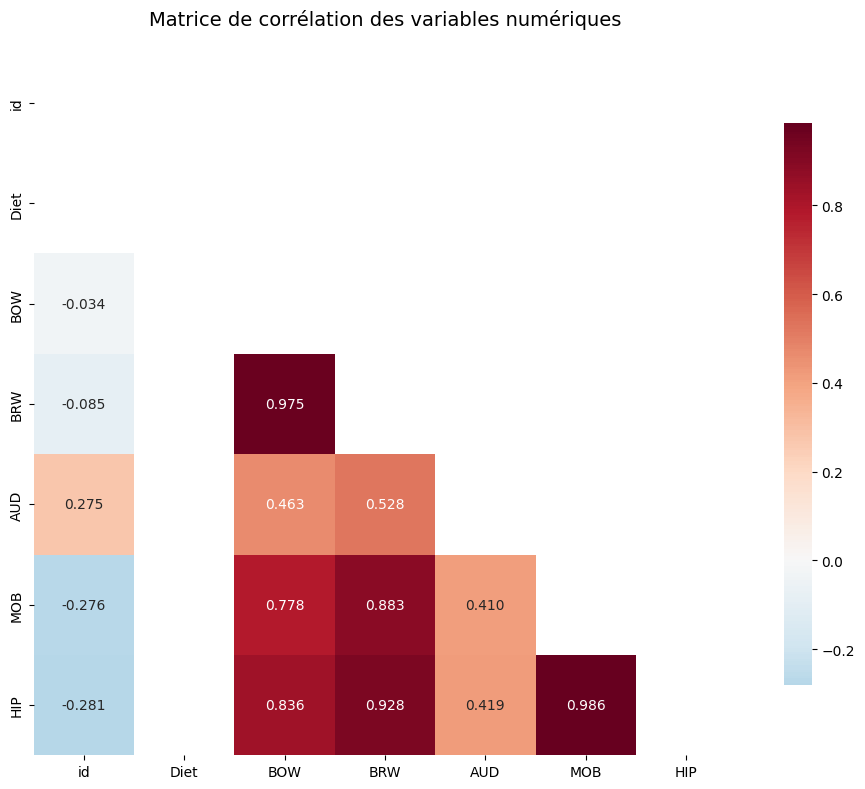

In [25]:
# Visualisation de la matrice de corrélation
fig, ax = plt.subplots(1, 1, figsize=(10, 8))
mask = np.triu(np.ones_like(correlation_matrix, dtype=bool))
sns.heatmap(correlation_matrix, annot=True, cmap='RdBu_r', center=0, 
            square=True, mask=mask, cbar_kws={"shrink": .8}, fmt='.3f')
ax.set_title('Matrice de corrélation des variables numériques', fontsize=14, pad=20)
plt.tight_layout()
plt.show()

In [27]:
# Test de significativité de la corrélation BOW-BRW
print(f"\n🧪 TEST DE SIGNIFICATIVITÉ DE LA CORRÉLATION BOW-BRW:")
from scipy.stats import pearsonr
corr_coef, p_value = pearsonr(df['BOW'], df['BRW'])
significance = "significative" if p_value < 0.05 else "non significative"
print(f"   • BOW-BRW: r={corr_coef:.4f}, p={p_value:.6f} - {significance}")


🧪 TEST DE SIGNIFICATIVITÉ DE LA CORRÉLATION BOW-BRW:
   • BOW-BRW: r=0.9747, p=0.000000 - significative


In [28]:
print(f"\n📈 VARIABLE EXPLICATIVE: BOW (Body mass)")
print(f"   • Corrélation avec BRW: {corr_coef:.4f} (très forte)")
print(f"   • Relation biologiquement logique: taille corporelle ↔ taille cerveau")
print(f"   • Significativité statistique confirmée (p < 0.001)")
print(f"   • Évite les problèmes de multicolinéarité")

print(f"\n⚠️ PROBLÈMES DE MULTICOLINÉARITÉ ÉVITÉS:")
print(f"   • MOB-HIP: r = {correlation_matrix.loc['MOB', 'HIP']:.4f} (quasi-redondance)")
print(f"   • BOW-HIP: r = {correlation_matrix.loc['BOW', 'HIP']:.4f} (élevée)")
print(f"   • BOW-MOB: r = {correlation_matrix.loc['BOW', 'MOB']:.4f} (modérée)")
print(f"   → En gardant seulement BOW, on évite ces problèmes")



📈 VARIABLE EXPLICATIVE: BOW (Body mass)
   • Corrélation avec BRW: 0.9747 (très forte)
   • Relation biologiquement logique: taille corporelle ↔ taille cerveau
   • Significativité statistique confirmée (p < 0.001)
   • Évite les problèmes de multicolinéarité

⚠️ PROBLÈMES DE MULTICOLINÉARITÉ ÉVITÉS:
   • MOB-HIP: r = 0.9856 (quasi-redondance)
   • BOW-HIP: r = 0.8361 (élevée)
   • BOW-MOB: r = 0.7784 (modérée)
   → En gardant seulement BOW, on évite ces problèmes


In [30]:
df_reg = df[['Species', 'BOW', 'BRW']].copy()
df_reg

,Species,BOW,BRW
0,Rousettus aegyptiacus,136.30,2070.00
1,Epomops franqueti,120.00,2210.00
2,Eonycteris spelaea,58.70,1310.00
3,Cynopterus sphinx,48.30,1184.33
4,Dobsonia praedatrix,184.00,3028.00
5,Glossophaga soricina,10.60,414.00
6,Leptonycteris curasoae,24.50,610.00
7,Macroglossus miniumus,14.60,561.00
8,Syconycteris australis,14.70,570.00
9,Nyctimene albiventer,29.70,825.00


In [31]:
print("\n" + "="*60)
print("PARTIE B : PREMIÈRE RÉGRESSION LINÉAIRE SIMPLE")
print("="*60)


PARTIE B : PREMIÈRE RÉGRESSION LINÉAIRE SIMPLE


In [40]:
# Préparation des données pour statsmodels
X = df_reg['BOW']
y = df_reg['BRW']
X_with_const = sm.add_constant(X)  # Ajout de la constante pour l'intercept

In [41]:
# Ajustement du modèle
model1 = sm.OLS(y, X_with_const).fit()

In [62]:
### 3. Affichage du résumé du modèle

print(" RÉSUMÉ DU MODÈLE 1 (avec toutes les données):")
print(model1.summary())

 RÉSUMÉ DU MODÈLE 1 (avec toutes les données):
                             OLS Regression Results                            
Dep. Variable:                     BRW   R-squared:                       0.950
Model:                             OLS   Adj. R-squared:                  0.948
Method:                  Least Squares   F-statistic:                     513.4
Date:              ven., 19 sept. 2025   Prob (F-statistic):           4.21e-19
Time:                         10:06:44   Log-Likelihood:                -213.64
No. Observations:                   29   AIC:                             431.3
Df Residuals:                       27   BIC:                             434.0
Df Model:                            1                                         
Covariance Type:             nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------

In [43]:
# Commentaires détaillés
print(f"\n📋 ANALYSE DÉTAILLÉE DU MODÈLE:")
print(f"{'='*40}")


📋 ANALYSE DÉTAILLÉE DU MODÈLE:


In [44]:
# Coefficients
intercept = model1.params[0]
slope = model1.params[1]
print(f"🔢 COEFFICIENTS ESTIMÉS:")
print(f"   Intercept (β₀): {intercept:.4f}")
print(f"   Pente (β₁): {slope:.4f}")
print(f"   → Équation: BRW = {intercept:.2f} + {slope:.4f} × BOW")

🔢 COEFFICIENTS ESTIMÉS:
   Intercept (β₀): 623.4469
   Pente (β₁): 8.9999
   → Équation: BRW = 623.45 + 8.9999 × BOW


In [45]:
# Signification statistique
p_intercept = model1.pvalues[0]
p_slope = model1.pvalues[1]
print(f"\n📈 SIGNIFICATION STATISTIQUE:")
print(f"   p-value intercept: {p_intercept:.6f} {'(significatif)' if p_intercept < 0.05 else '(non significatif)'}")
print(f"   p-value pente: {p_slope:.6f} {'(significatif)' if p_slope < 0.05 else '(non significatif)'}")



📈 SIGNIFICATION STATISTIQUE:
   p-value intercept: 0.000000 (significatif)
   p-value pente: 0.000000 (significatif)


In [46]:
# R²
r_squared = model1.rsquared
adj_r_squared = model1.rsquared_adj
print(f"\n📊 COEFFICIENT DE DÉTERMINATION:")
print(f"   R²: {r_squared:.4f} ({r_squared*100:.1f}% de variance expliquée)")
print(f"   R² ajusté: {adj_r_squared:.4f}")


📊 COEFFICIENT DE DÉTERMINATION:
   R²: 0.9500 (95.0% de variance expliquée)
   R² ajusté: 0.9482


In [47]:
print(f"\n🔍 ANALYSE DES RÉSIDUS:")
print(f"{'='*30}")

# Calcul des résidus
residuals = model1.resid
fitted_values = model1.fittedvalues

# Tests statistiques sur les résidus
shapiro_stat, shapiro_p = stats.shapiro(residuals)
print(f"Test de normalité (Shapiro-Wilk): p = {shapiro_p:.6f}")
print(f"   → {'Résidus normaux' if shapiro_p > 0.05 else 'Résidus non normaux'}")



🔍 ANALYSE DES RÉSIDUS:
Test de normalité (Shapiro-Wilk): p = 0.005526
   → Résidus non normaux


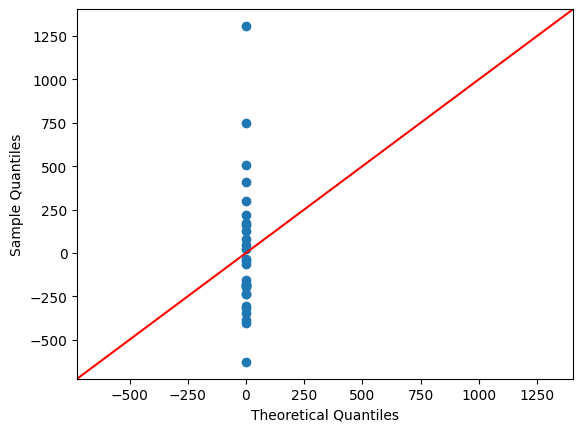

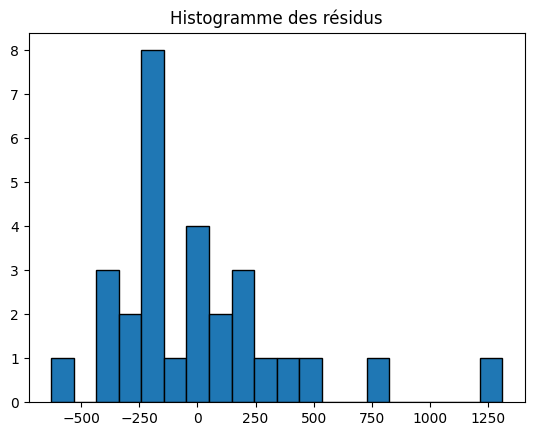

In [49]:
import matplotlib.pyplot as plt
import statsmodels.api as sm

sm.qqplot(residuals, line="45")
plt.show()

plt.hist(residuals, bins=20, edgecolor="black")
plt.title("Histogramme des résidus")
plt.show()


In [48]:
# Durbin-Watson pour l'autocorrélation
from statsmodels.stats.diagnostic import acorr_ljungbox
try:
    dw_stat = sm.stats.stattools.durbin_watson(residuals)
    print(f"Test Durbin-Watson: {dw_stat:.4f}")
    if 1.5 < dw_stat < 2.5:
        print("   → Pas d'autocorrélation")
    else:
        print("   → Possible autocorrélation")
except:
    print("Test Durbin-Watson non disponible")

Test Durbin-Watson: 2.4751
   → Pas d'autocorrélation


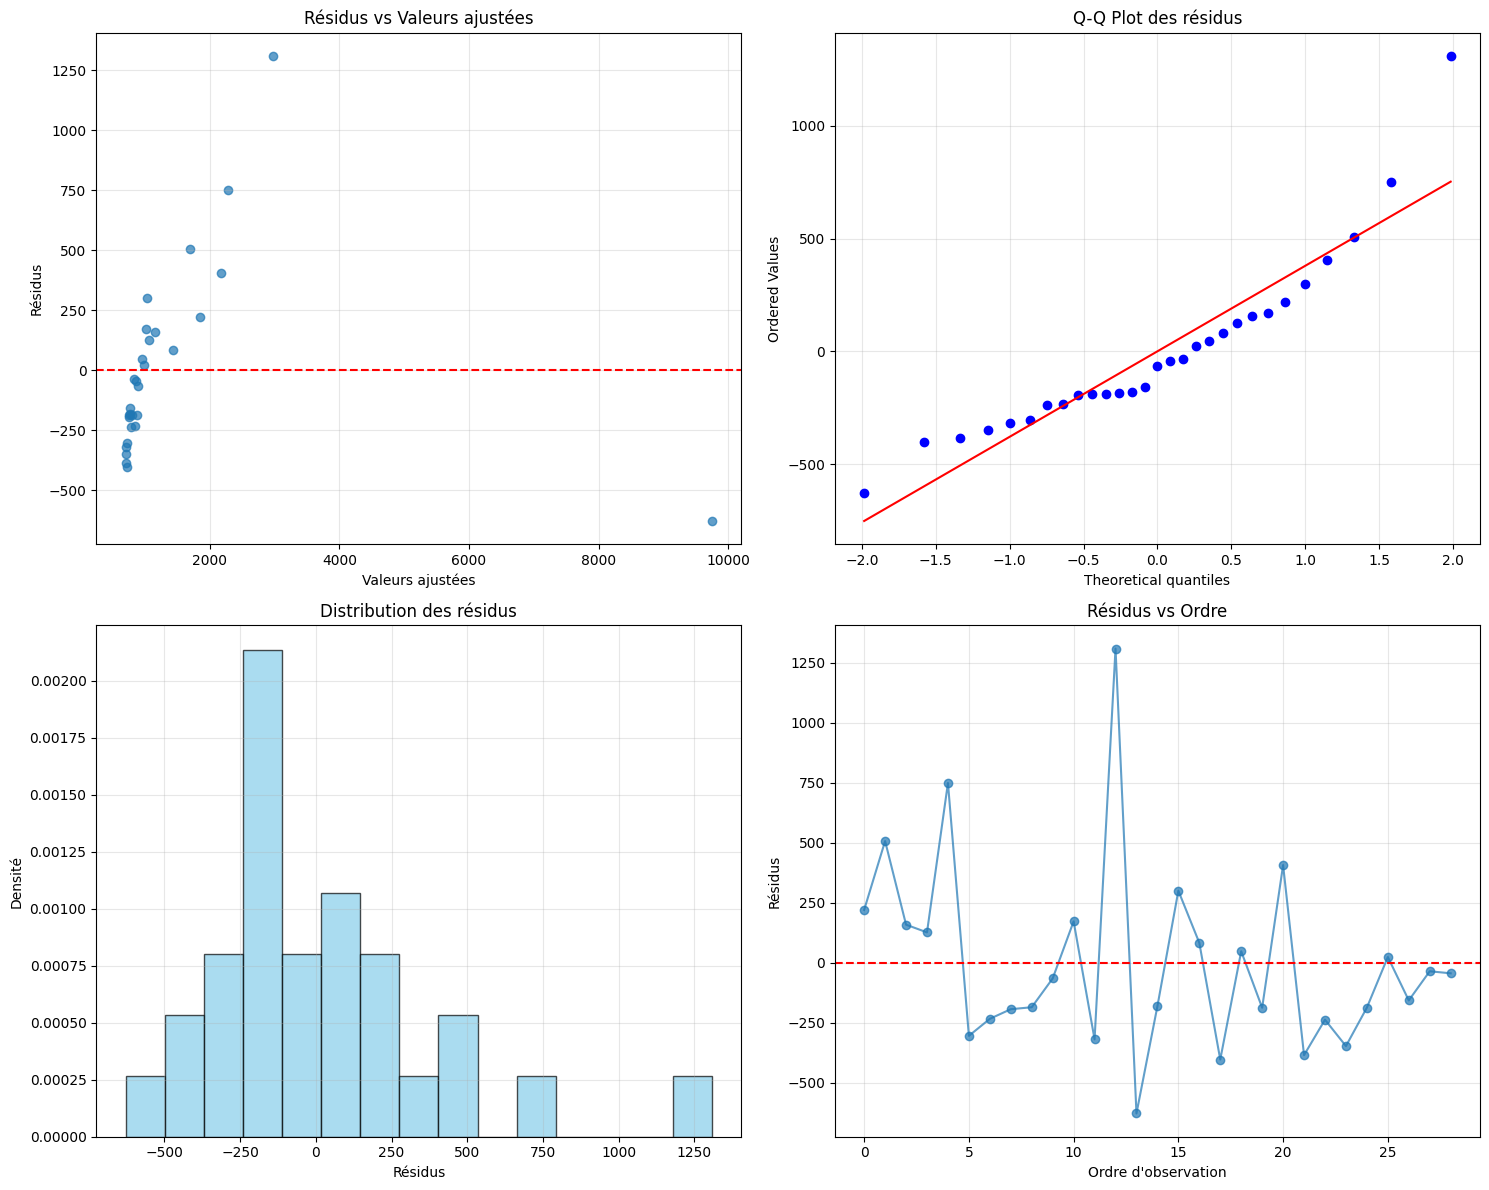

In [50]:
# Graphiques des résidus
fig, axes = plt.subplots(2, 2, figsize=(15, 12))

# 1. Résidus vs valeurs ajustées
axes[0,0].scatter(fitted_values, residuals, alpha=0.7)
axes[0,0].axhline(y=0, color='red', linestyle='--')
axes[0,0].set_xlabel('Valeurs ajustées')
axes[0,0].set_ylabel('Résidus')
axes[0,0].set_title('Résidus vs Valeurs ajustées')
axes[0,0].grid(True, alpha=0.3)

# 2. Q-Q plot pour la normalité
stats.probplot(residuals, dist="norm", plot=axes[0,1])
axes[0,1].set_title('Q-Q Plot des résidus')
axes[0,1].grid(True, alpha=0.3)

# 3. Histogramme des résidus
axes[1,0].hist(residuals, bins=15, density=True, alpha=0.7, color='skyblue', edgecolor='black')
axes[1,0].set_xlabel('Résidus')
axes[1,0].set_ylabel('Densité')
axes[1,0].set_title('Distribution des résidus')
axes[1,0].grid(True, alpha=0.3)

# 4. Résidus vs ordre d'observation
axes[1,1].plot(range(len(residuals)), residuals, 'o-', alpha=0.7)
axes[1,1].axhline(y=0, color='red', linestyle='--')
axes[1,1].set_xlabel('Ordre d\'observation')
axes[1,1].set_ylabel('Résidus')
axes[1,1].set_title('Résidus vs Ordre')
axes[1,1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


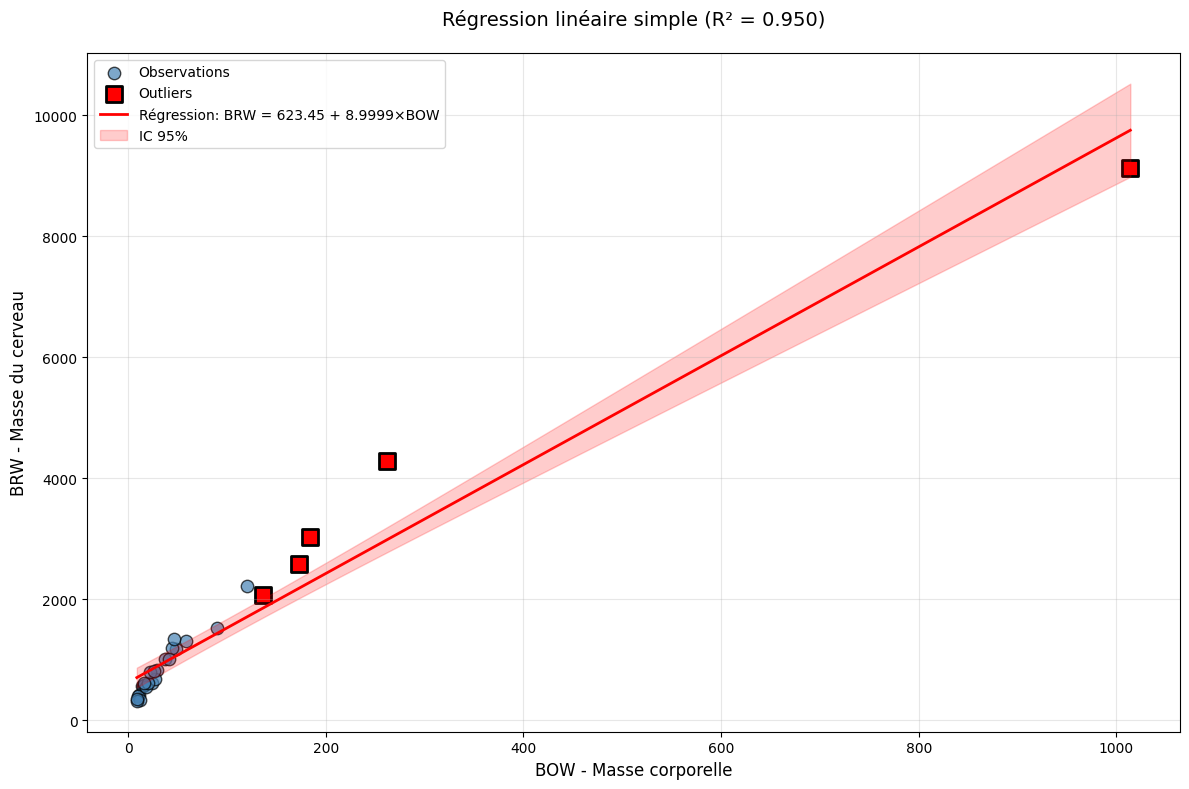

In [51]:
### 5. Tracé de la droite de régression

fig, ax = plt.subplots(1, 1, figsize=(12, 8))

# Nuage de points
ax.scatter(df_reg['BOW'], df_reg['BRW'], alpha=0.7, s=80, c='steelblue', 
          edgecolors='black', label='Observations')

# Outliers en rouge
if not outliers.empty:
    ax.scatter(outliers['BOW'], outliers['BRW'], c='red', s=120, marker='s', 
              label=f'Outliers', edgecolors='black', linewidth=2)

# Droite de régression
x_range = np.linspace(df_reg['BOW'].min(), df_reg['BOW'].max(), 100)
y_pred = intercept + slope * x_range
ax.plot(x_range, y_pred, 'red', linewidth=2, 
        label=f'Régression: BRW = {intercept:.2f} + {slope:.4f}×BOW')

# Intervalle de confiance (optionnel)
predictions = model1.get_prediction(sm.add_constant(x_range))
pred_summary = predictions.summary_frame(alpha=0.05)

ax.fill_between(x_range, pred_summary['mean_ci_lower'], pred_summary['mean_ci_upper'], 
                alpha=0.2, color='red', label='IC 95%')

ax.set_xlabel('BOW - Masse corporelle', fontsize=12)
ax.set_ylabel('BRW - Masse du cerveau', fontsize=12)
ax.set_title(f'Régression linéaire simple (R² = {r_squared:.3f})', fontsize=14, pad=20)
ax.grid(True, alpha=0.3)
ax.legend()

plt.tight_layout()
plt.show()


In [52]:
print("\n" + "="*60)
print("PARTIE C : ANALYSE AVEC RETRAIT D'ESPÈCE ATYPIQUE")
print("="*60)



PARTIE C : ANALYSE AVEC RETRAIT D'ESPÈCE ATYPIQUE


In [54]:
### 1. Création du second tableau sans Pteropus vampyrus

print("🔍 Recherche de l'espèce Pteropus vampyrus...")

# Recherche de Pteropus vampyrus
pteropus_mask = df_reg['Species'].str.contains('Pteropus vampyrus', case=False, na=False)
has_pteropus = pteropus_mask.any()

has_pteropus

🔍 Recherche de l'espèce Pteropus vampyrus...


np.True_

In [55]:
if has_pteropus:
    print("✓ Pteropus vampyrus trouvé dans les données")
    pteropus_data = df_reg[pteropus_mask]
    print(f"Données de Pteropus vampyrus:")
    print(pteropus_data)
    
    # Création du dataset sans Pteropus vampyrus
    tab2 = df_reg[~pteropus_mask].copy()
    print(f"\nDataset original: {len(df_reg)} observations")
    print(f"Dataset tab2 (sans Pteropus vampyrus): {len(tab2)} observations")
else:
    print("❌ Pteropus vampyrus non trouvé dans les données")
    print("→ Retrait du plus gros outlier à la place")
    
    # Retrait du plus gros outlier basé sur la distance de Mahalanobis ou distance euclidienne
    if not outliers.empty:
        # Retrait du premier outlier trouvé
        outlier_to_remove = outliers.index[0]
        tab2 = df_reg.drop(outlier_to_remove).copy()
        removed_species = df_reg.loc[outlier_to_remove, 'Species']
        print(f"→ Retrait de {removed_species}")
    else:
        # Retrait de l'observation la plus extrême
        distances = ((df_reg['BOW'] - df_reg['BOW'].mean())**2 + 
                    (df_reg['BRW'] - df_reg['BRW'].mean())**2)**0.5
        outlier_idx = distances.idxmax()
        tab2 = df_reg.drop(outlier_idx).copy()
        removed_species = df_reg.loc[outlier_idx, 'Species']
        print(f"→ Retrait de {removed_species} (observation la plus extrême)")
    
    print(f"\nDataset original: {len(df_reg)} observations")
    print(f"Dataset tab2: {len(tab2)} observations")


✓ Pteropus vampyrus trouvé dans les données
Données de Pteropus vampyrus:
              Species     BOW     BRW
13  Pteropus vampyrus  1014.0  9121.0

Dataset original: 29 observations
Dataset tab2 (sans Pteropus vampyrus): 28 observations


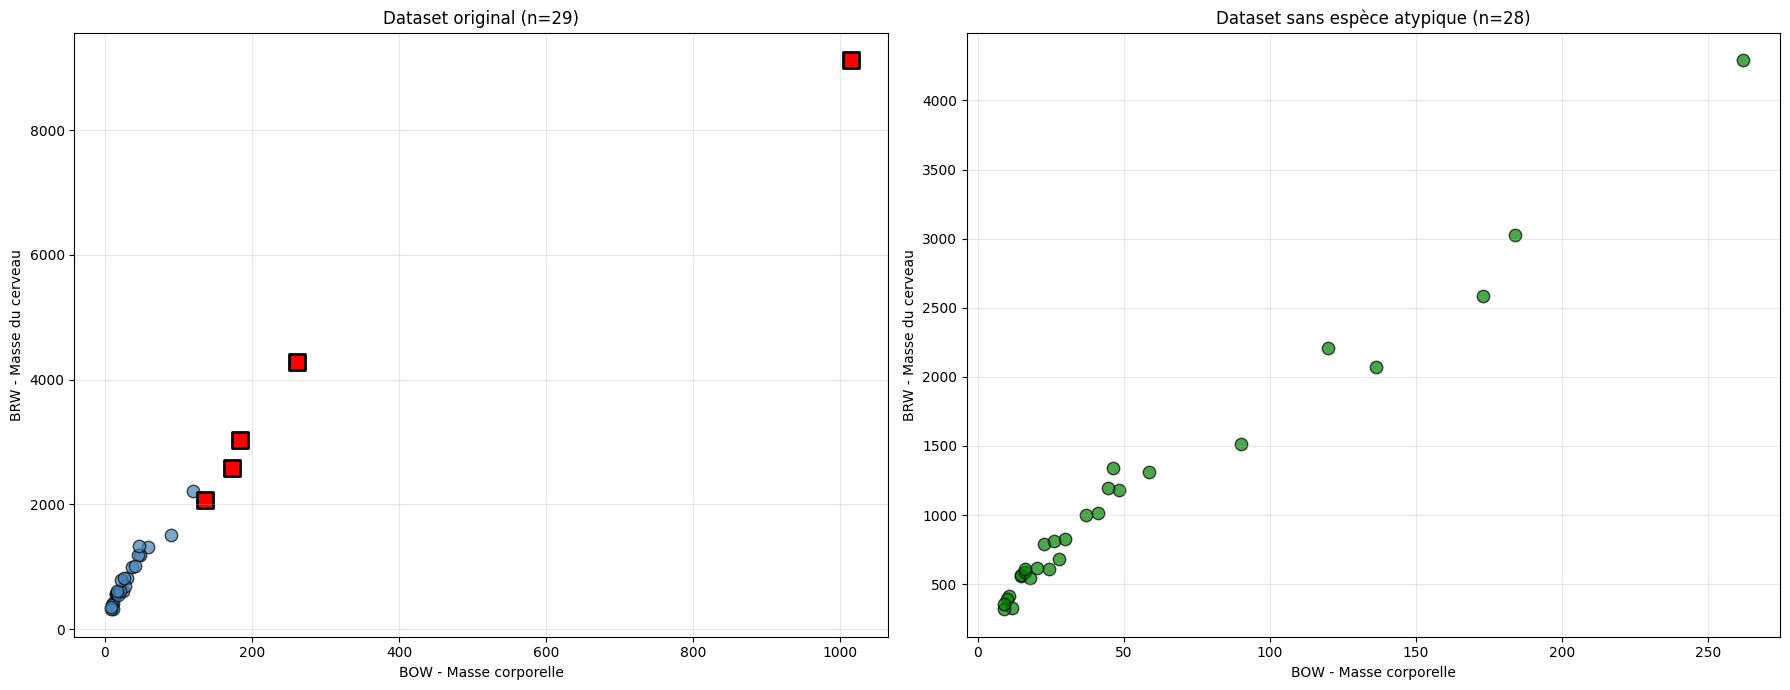

In [56]:
### 2. Comparaison visuelle des nuages de points

fig, axes = plt.subplots(1, 2, figsize=(18, 7))

# Dataset original
axes[0].scatter(df_reg['BOW'], df_reg['BRW'], alpha=0.7, s=80, c='steelblue', 
               edgecolors='black')
if not outliers.empty:
    axes[0].scatter(outliers['BOW'], outliers['BRW'], c='red', s=120, marker='s', 
                   edgecolors='black', linewidth=2)
    
axes[0].set_xlabel('BOW - Masse corporelle')
axes[0].set_ylabel('BRW - Masse du cerveau')
axes[0].set_title(f'Dataset original (n={len(df_reg)})')
axes[0].grid(True, alpha=0.3)

# Dataset sans espèce atypique
axes[1].scatter(tab2['BOW'], tab2['BRW'], alpha=0.7, s=80, c='green', 
               edgecolors='black')
axes[1].set_xlabel('BOW - Masse corporelle')
axes[1].set_ylabel('BRW - Masse du cerveau')
axes[1].set_title(f'Dataset sans espèce atypique (n={len(tab2)})')
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [57]:
### 3. Ajustement du second modèle et comparaison

print(f"\n{'='*50}")
print("AJUSTEMENT DU MODÈLE 2 (sans espèce atypique)")
print("="*50)

# Ajustement du second modèle
X2 = tab2['BOW']
y2 = tab2['BRW']
X2_with_const = sm.add_constant(X2)

model2 = sm.OLS(y2, X2_with_const).fit()


AJUSTEMENT DU MODÈLE 2 (sans espèce atypique)


In [58]:
print("\n📊 RÉSUMÉ DU MODÈLE 2:")
print(model2.summary())

# Comparaison des modèles
print(f"\n{'='*60}")
print("COMPARAISON DES DEUX MODÈLES")
print("="*60)



📊 RÉSUMÉ DU MODÈLE 2:
                             OLS Regression Results                            
Dep. Variable:                     BRW   R-squared:                       0.978
Model:                             OLS   Adj. R-squared:                  0.977
Method:                  Least Squares   F-statistic:                     1147.
Date:              ven., 19 sept. 2025   Prob (F-statistic):           4.91e-23
Time:                         10:02:39   Log-Likelihood:                -177.41
No. Observations:                   28   AIC:                             358.8
Df Residuals:                       26   BIC:                             361.5
Df Model:                            1                                         
Covariance Type:             nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const        346.54

In [59]:
# Coefficients
print(f"🔢 COEFFICIENTS:")
print(f"                 Modèle 1 (complet)    Modèle 2 (sans outlier)")
print(f"Intercept:       {model1.params[0]:>12.4f}        {model2.params[0]:>12.4f}")
print(f"Pente:           {model1.params[1]:>12.4f}        {model2.params[1]:>12.4f}")

# R²
print(f"\n📊 COEFFICIENT DE DÉTERMINATION:")
print(f"R² Modèle 1:     {model1.rsquared:.4f} ({model1.rsquared*100:.1f}%)")
print(f"R² Modèle 2:     {model2.rsquared:.4f} ({model2.rsquared*100:.1f}%)")
print(f"Différence:      {model2.rsquared - model1.rsquared:+.4f}")

# Erreur standard des résidus
mse1 = model1.mse_resid
mse2 = model2.mse_resid
print(f"\n📈 ERREUR QUADRATIQUE MOYENNE:")
print(f"MSE Modèle 1:    {mse1:.4f}")
print(f"MSE Modèle 2:    {mse2:.4f}")
print(f"Amélioration:    {((mse1 - mse2) / mse1 * 100):+.1f}%")

🔢 COEFFICIENTS:
                 Modèle 1 (complet)    Modèle 2 (sans outlier)
Intercept:           623.4469            346.5452
Pente:                 8.9999             14.5099

📊 COEFFICIENT DE DÉTERMINATION:
R² Modèle 1:     0.9500 (95.0%)
R² Modèle 2:     0.9778 (97.8%)
Différence:      +0.0278

📈 ERREUR QUADRATIQUE MOYENNE:
MSE Modèle 1:    157549.5698
MSE Modèle 2:    20095.7735
Amélioration:    +87.2%


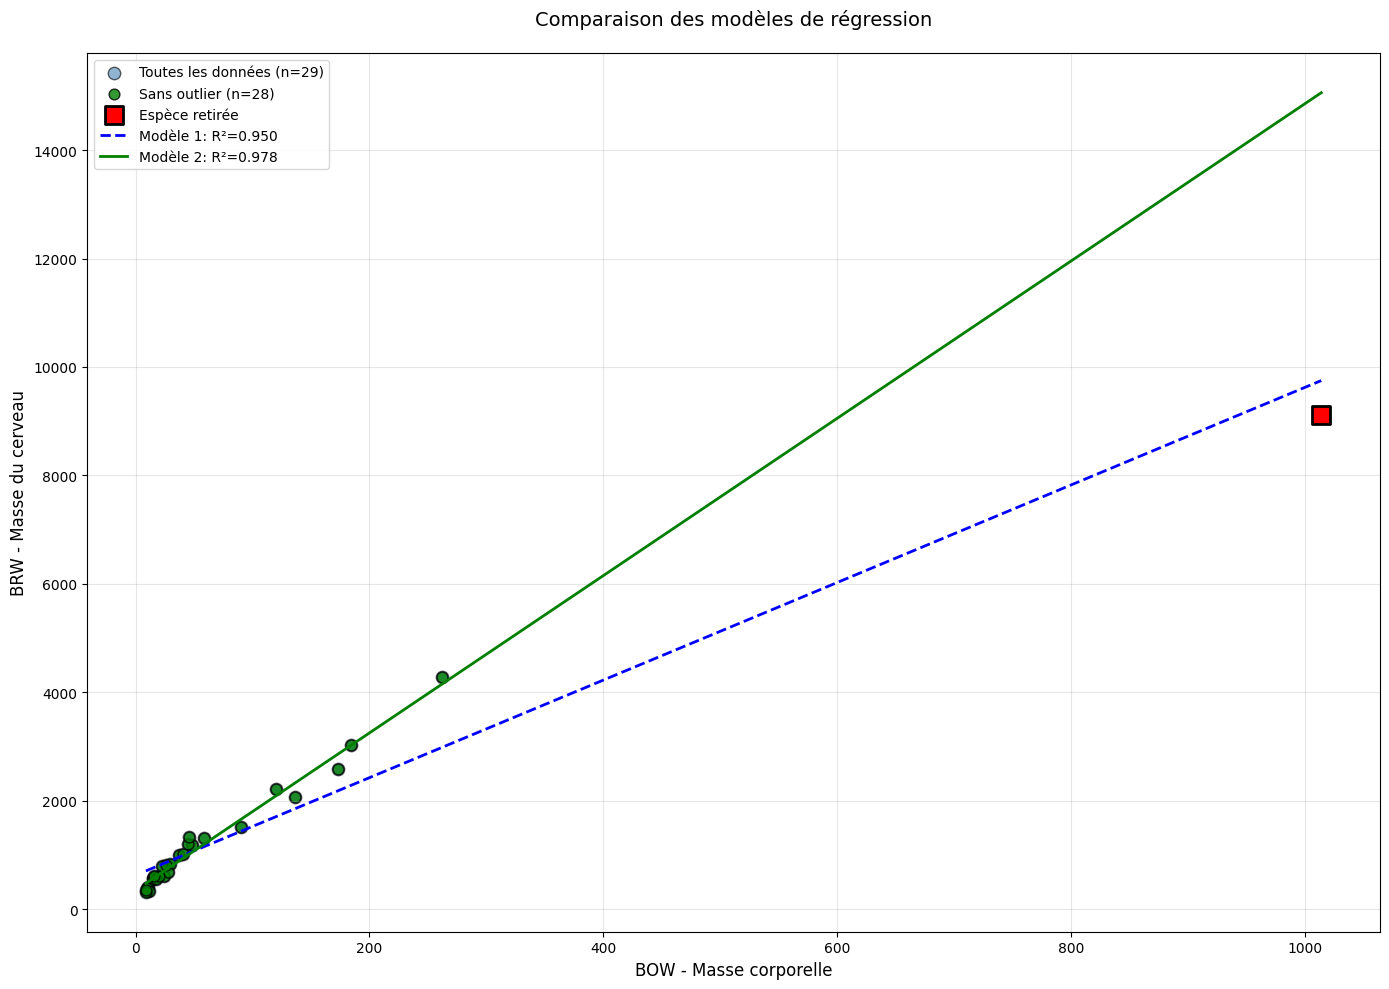

In [60]:
### 4. Superposition des deux droites de régression

fig, ax = plt.subplots(1, 1, figsize=(14, 10))

# Données complètes en bleu
ax.scatter(df_reg['BOW'], df_reg['BRW'], alpha=0.6, s=80, c='steelblue', 
          edgecolors='black', label=f'Toutes les données (n={len(df_reg)})')

# Données sans outlier en vert
ax.scatter(tab2['BOW'], tab2['BRW'], alpha=0.8, s=60, c='green', 
          edgecolors='black', label=f'Sans outlier (n={len(tab2)})')

# Espèce retirée en rouge
removed_data = df_reg[~df_reg.index.isin(tab2.index)]
if not removed_data.empty:
    ax.scatter(removed_data['BOW'], removed_data['BRW'], c='red', s=150, marker='s', 
              edgecolors='black', linewidth=2, label='Espèce retirée')

# Droites de régression
x_range = np.linspace(df_reg['BOW'].min(), df_reg['BOW'].max(), 100)

# Modèle 1 (complet)
y1_pred = model1.params[0] + model1.params[1] * x_range
ax.plot(x_range, y1_pred, 'blue', linewidth=2, linestyle='--',
        label=f'Modèle 1: R²={model1.rsquared:.3f}')

# Modèle 2 (sans outlier)
y2_pred = model2.params[0] + model2.params[1] * x_range
ax.plot(x_range, y2_pred, 'green', linewidth=2, linestyle='-',
        label=f'Modèle 2: R²={model2.rsquared:.3f}')

ax.set_xlabel('BOW - Masse corporelle', fontsize=12)
ax.set_ylabel('BRW - Masse du cerveau', fontsize=12)
ax.set_title('Comparaison des modèles de régression', fontsize=14, pad=20)
ax.grid(True, alpha=0.3)
ax.legend(fontsize=10)

plt.tight_layout()
plt.show()


In [61]:
### Commentaires sur l'effet de l'espèce atypique

print(f"\n{'='*60}")
print("COMMENTAIRES SUR L'EFFET DE L'ESPÈCE ATYPIQUE")
print("="*60)

print(f"📝 IMPACT DE L'ESPÈCE ATYPIQUE:")

# Changement de R²
r2_change = model2.rsquared - model1.rsquared
if r2_change > 0.05:
    print(f"   • Amélioration substantielle du R² (+{r2_change:.3f})")
elif r2_change > 0.01:
    print(f"   • Amélioration modérée du R² (+{r2_change:.3f})")
else:
    print(f"   • Amélioration faible du R² (+{r2_change:.3f})")

# Changement de pente
slope_change = model2.params[1] - model1.params[1]
slope_change_pct = (slope_change / model1.params[1]) * 100
print(f"   • Changement de pente: {slope_change:+.4f} ({slope_change_pct:+.1f}%)")

# Changement d'intercept
intercept_change = model2.params[0] - model1.params[0]
print(f"   • Changement d'intercept: {intercept_change:+.4f}")

# Amélioration de l'erreur
mse_improvement = ((mse1 - mse2) / mse1) * 100
print(f"   • Réduction de l'erreur quadratique: {mse_improvement:.1f}%")

print(f"\n🎯 CONCLUSION:")
if r2_change > 0.1 and mse_improvement > 20:
    print("   L'espèce atypique avait un impact majeur sur le modèle.")
    print("   Son retrait améliore significativement la qualité de l'ajustement.")
elif r2_change > 0.05 and mse_improvement > 10:
    print("   L'espèce atypique avait un impact modéré sur le modèle.")
    print("   Son retrait améliore la qualité de l'ajustement.")
else:
    print("   L'espèce atypique avait un impact limité sur le modèle.")
    print("   Son retrait n'améliore que légèrement l'ajustement.")

print(f"\n💡 RECOMMANDATIONS:")
if model2.rsquared > 0.8:
    print("   • Le modèle sans outlier montre un excellent ajustement")
elif model2.rsquared > 0.6:
    print("   • Le modèle sans outlier montre un bon ajustement")
else:
    print("   • L'ajustement reste modéré même sans l'outlier")

if r2_change > 0.05:
    print("   • Il est recommandé d'utiliser le modèle sans l'espèce atypique")
    print("   • Investiguer les causes de cette valeur atypique")
else:
    print("   • Les deux modèles donnent des résultats similaires")
    print("   • Le choix du modèle dépend du contexte d'application")

print(f"\n{'='*60}")
print("FIN DU TP 2 - RÉGRESSION LINÉAIRE")
print("="*60)


COMMENTAIRES SUR L'EFFET DE L'ESPÈCE ATYPIQUE
📝 IMPACT DE L'ESPÈCE ATYPIQUE:
   • Amélioration modérée du R² (+0.028)
   • Changement de pente: +5.5100 (+61.2%)
   • Changement d'intercept: -276.9017
   • Réduction de l'erreur quadratique: 87.2%

🎯 CONCLUSION:
   L'espèce atypique avait un impact limité sur le modèle.
   Son retrait n'améliore que légèrement l'ajustement.

💡 RECOMMANDATIONS:
   • Le modèle sans outlier montre un excellent ajustement
   • Les deux modèles donnent des résultats similaires
   • Le choix du modèle dépend du contexte d'application

FIN DU TP 2 - RÉGRESSION LINÉAIRE
